In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
df=pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\azerbaycan_demoqrafiya_1935_2025.csv")
df.head()

,Il,Ortalama_Ehali,Diri_Dogumlar,Olumler,Tebii_Artim,Dogum_Emsali_1000de,Olum_Emsali_1000de,Tebii_Artim_Emsali_1000de,Migrasiya_Emsali_1000de,Umumi_Dogusluq_Emsali
0,1935,2933800,65245,32134,33111,22.0,10.8,11.2,NaN,NaN
1,1936,3004300,75761,34966,40795,24.9,11.5,13.4,10.6,NaN
2,1937,3082600,110341,40787,69554,35.3,13.1,22.2,3.9,NaN
3,1938,3167400,99729,40937,58792,31.3,12.8,18.5,9.0,NaN
4,1939,3205200,101529,39828,61701,31.4,12.3,19.1,-7.2,NaN


Ümumi artım: 249.15808848592272 %
Ortalama illik artım tempi: 1.4137890981797703 %
Ən sürətli artım ili: 1961
Ən yavaş/mənfi artım ili: 1943


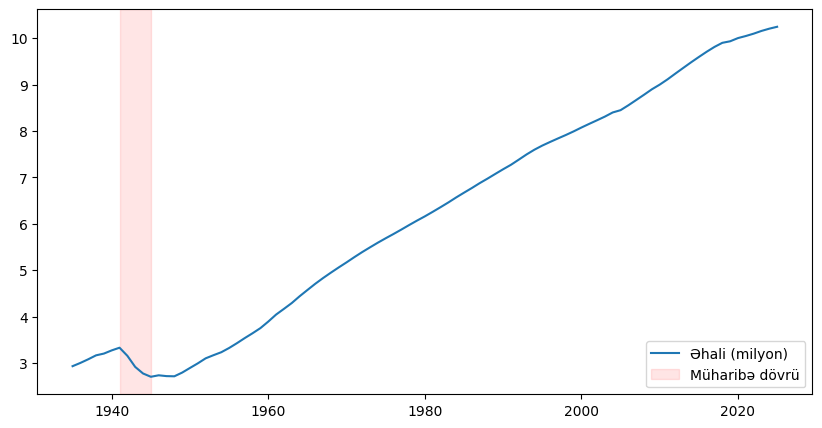

In [3]:
df['Ehali_MA5'] = df['Ortalama_Ehali'].rolling(5, center=True).mean()
df['Dogum_MA5'] = df['Dogum_Emsali_1000de'].rolling(5, center=True).mean()
df['Olum_MA5'] = df['Olum_Emsali_1000de'].rolling(5, center=True).mean()
df['TebiiArtim_MA5'] = df['Tebii_Artim_Emsali_1000de'].rolling(5, center=True).mean()

df['Ehali_Artim_Perc'] = df['Ortalama_Ehali'].pct_change() * 100

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(df['Il'], df['Ortalama_Ehali']/1e6, label='Əhali (milyon)')
ax.axvspan(1941, 1945, color='red', alpha=0.1, label='Müharibə dövrü')
ax.legend()

print("Ümumi artım:", (df.iloc[-1]['Ortalama_Ehali']/df.iloc[0]['Ortalama_Ehali']-1)*100, "%")
print("Ortalama illik artım tempi:", df['Ehali_Artim_Perc'].mean(), "%")
print("Ən sürətli artım ili:", df.loc[df['Ehali_Artim_Perc'].idxmax(),'Il'])
print("Ən yavaş/mənfi artım ili:", df.loc[df['Ehali_Artim_Perc'].idxmin(),'Il'])

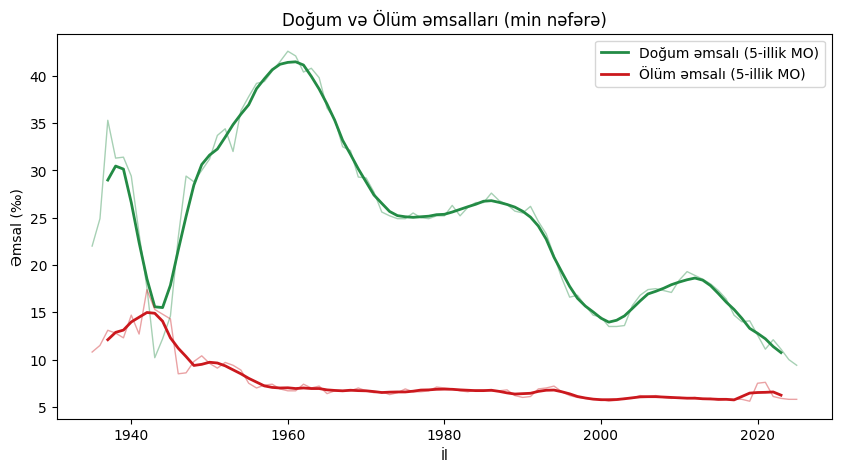

In [4]:
fig, ax = plt.subplots(figsize=(10,5))

ax.plot(df['Il'], df['Dogum_Emsali_1000de'], color='#238b45', linewidth=1, alpha=0.4)
ax.plot(df['Il'], df['Dogum_MA5'], color='#238b45', linewidth=2, label='Doğum əmsalı (5-illik MO)')

ax.plot(df['Il'], df['Olum_Emsali_1000de'], color='#cb181d', linewidth=1, alpha=0.4)
ax.plot(df['Il'], df['Olum_MA5'], color='#cb181d', linewidth=2, label='Ölüm əmsalı (5-illik MO)')

ax.set_title('Doğum və Ölüm əmsalları (min nəfərə)')
ax.set_xlabel('İl'); ax.set_ylabel('Əmsal (‰)')
ax.legend()

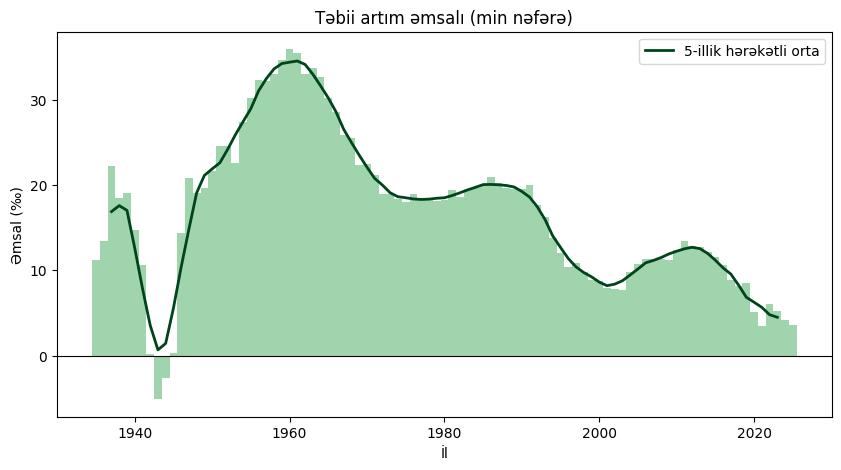

In [5]:
fig, ax = plt.subplots(figsize=(10,5))

ax.bar(df['Il'], df['Tebii_Artim_Emsali_1000de'], color='#41ab5d', width=1, alpha=0.5)

ax.plot(df['Il'], df['TebiiArtim_MA5'], color='#00441b', linewidth=2, label='5-illik hərəkətli orta')

ax.axhline(0, color='black', linewidth=0.8)

ax.set_title('Təbii artım əmsalı (min nəfərə)')
ax.set_xlabel('İl'); ax.set_ylabel('Əmsal (‰)')
ax.legend()

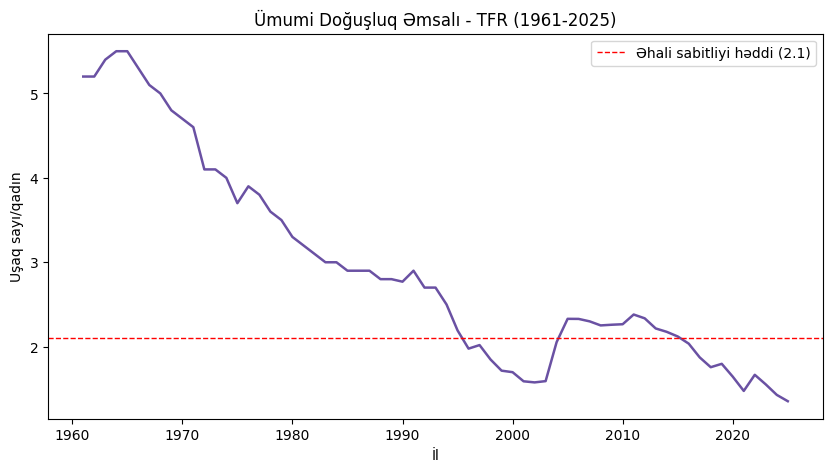

In [6]:
fig, ax = plt.subplots(figsize=(10,5))

tfr = df.dropna(subset=['Umumi_Dogusluq_Emsali'])

ax.plot(tfr['Il'], tfr['Umumi_Dogusluq_Emsali'], color='#6a51a3', linewidth=1.8)

ax.axhline(2.1, color='red', linestyle='--', linewidth=1, label='Əhali sabitliyi həddi (2.1)')

ax.set_title('Ümumi Doğuşluq Əmsalı - TFR (1961-2025)')
ax.set_xlabel('İl'); ax.set_ylabel('Uşaq sayı/qadın')
ax.legend()

In [7]:
X1 = df['Il']
y1 = df['Dogum_Emsali_1000de']

X1 = sm.add_constant(X1)  
model1 = sm.OLS(y1, X1).fit()

print(model1.summary())

                             OLS Regression Results                            
Dep. Variable:     Dogum_Emsali_1000de   R-squared:                       0.435
Model:                             OLS   Adj. R-squared:                  0.429
Method:                  Least Squares   F-statistic:                     68.55
Date:                 Fri, 30 Oct 2026   Prob (F-statistic):           1.16e-12
Time:                         17:32:22   Log-Likelihood:                -301.52
No. Observations:                   91   AIC:                             607.0
Df Residuals:                       89   BIC:                             612.1
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        464.2167     53.131      8.73

In [8]:
recent = df[df['Il']>=1996]
X2 = recent['Il']
y2 = recent['Dogum_Emsali_1000de']

X2 = sm.add_constant(X2)
model2 = sm.OLS(y2, X2).fit()

print(model2.summary())

il_2030 = [1, 2030]  
proqnoz_2030 = model2.predict(il_2030)
print("\n2030 üçün doğum əmsalı proqnozu:", proqnoz_2030[0])

                             OLS Regression Results                            
Dep. Variable:     Dogum_Emsali_1000de   R-squared:                       0.215
Model:                             OLS   Adj. R-squared:                  0.186
Method:                  Least Squares   F-statistic:                     7.648
Date:                 Fri, 30 Oct 2026   Prob (F-statistic):            0.00994
Time:                         17:32:22   Log-Likelihood:                -68.395
No. Observations:                   30   AIC:                             140.8
Df Residuals:                       28   BIC:                             143.6
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        302.3704    103.831      2.91

In [9]:

tfr = df.dropna(subset=['Umumi_Dogusluq_Emsali'])
X3 = tfr['Il'].values
y3 = tfr['Umumi_Dogusluq_Emsali'].values

coeffs = np.polyfit(X3, y3, 3)   
poly = np.poly1d(coeffs)         
y3_pred = poly(X3)
r2_3 = r2_score(y3, y3_pred)

proqnoz_2030 = poly(2030)
print("2030 üçün TFR proqnozu:", proqnoz_2030)

2030 üçün TFR proqnozu: 1.5243752134847455


In [10]:
mreg_df = df.dropna(subset=['Dogum_Emsali_1000de','Olum_Emsali_1000de',
                              'Migrasiya_Emsali_1000de','Tebii_Artim_Emsali_1000de'])

Xm = mreg_df[['Dogum_Emsali_1000de','Olum_Emsali_1000de','Migrasiya_Emsali_1000de']]
ym = mreg_df['Tebii_Artim_Emsali_1000de']

Xm = sm.add_constant(Xm)
model4 = sm.OLS(ym, Xm).fit()

print(model4.summary())

                                OLS Regression Results                               
Dep. Variable:     Tebii_Artim_Emsali_1000de   R-squared:                       1.000
Model:                                   OLS   Adj. R-squared:                  1.000
Method:                        Least Squares   F-statistic:                 1.105e+06
Date:                       Fri, 30 Oct 2026   Prob (F-statistic):          4.71e-197
Time:                               17:32:22   Log-Likelihood:                 150.06
No. Observations:                         90   AIC:                            -292.1
Df Residuals:                             86   BIC:                            -282.1
Df Model:                                  3                                         
Covariance Type:                   nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------

In [11]:
sovet = df[df['Il']<=1990]['Dogum_Emsali_1000de']
mustaqil = df[df['Il']>1990]['Dogum_Emsali_1000de']
print("sovet:", stats.shapiro(sovet).pvalue)
print("mustaqil:", stats.shapiro(mustaqil).pvalue)
l_stat, l_p=stats.levene(sovet, mustaqil)
print("Levene", l_p)
t_stat, p_value = stats.ttest_ind(sovet, mustaqil, equal_var=False)

print("Sovet dövrü - orta:", sovet.mean(), "n=", len(sovet))
print("Müstəqillik dövrü - orta:", mustaqil.mean(), "n=", len(mustaqil))
print("t-statistikası:", t_stat)
print("p-dəyəri:", p_value)

sovet: 0.020099678565935804
mustaqil: 0.2895594897907856
Levene 0.0014715633154545214
Sovet dövrü - orta: 29.410714285714285 n= 56
Müstəqillik dövrü - orta: 16.294285714285714 n= 35
t-statistikası: 11.235289906371428
p-dəyəri: 1.3307655466028539e-18


In [12]:
muharibe = df[(df['Il']>=1941)&(df['Il']<=1945)]['Olum_Emsali_1000de']
sulh = df[((df['Il']>=1935)&(df['Il']<=1940)) | ((df['Il']>=1946)&(df['Il']<=1955))]['Olum_Emsali_1000de']

t_stat2, p_value2 = stats.ttest_ind(muharibe, sulh, equal_var=False)

print("Müharibə dövrü - orta:", muharibe.mean(), "n=", len(muharibe))
print("Sülh dövrü - orta:", sulh.mean(), "n=", len(sulh))
print("t:", t_stat2, "p:", p_value2)

Müharibə dövrü - orta: 14.9 n= 5
Sülh dövrü - orta: 10.41875 n= 16
t: 4.938130518713478 p: 0.0012823935196815618


In [13]:
covid = df[(df['Il']>=2020)&(df['Il']<=2021)]['Olum_Emsali_1000de']
pre_covid = df[(df['Il']>=2015)&(df['Il']<=2019)]['Olum_Emsali_1000de']

t_stat3, p_value3 = stats.ttest_ind(covid, pre_covid, equal_var=False)

print("COVID dövrü - orta:", covid.mean(), "n=", len(covid))
print("COVID-öncəsi - orta:", pre_covid.mean(), "n=", len(pre_covid))
print("t:", t_stat3, "p:", p_value3)

COVID dövrü - orta: 7.55 n= 2
COVID-öncəsi - orta: 5.74 n= 5
t: 28.267450901837748 p: 0.00039382046432993097


In [14]:
tfr_df = df.dropna(subset=['Dogum_Emsali_1000de','Umumi_Dogusluq_Emsali'])

r1, p1 = stats.pearsonr(tfr_df['Dogum_Emsali_1000de'], tfr_df['Umumi_Dogusluq_Emsali'])

print("Pearson r:", r1)
print("p-dəyər:", p1)

Pearson r: 0.9389463908646627
p-dəyər: 6.842943715392649e-31


In [15]:
mig_df = df.dropna(subset=['Migrasiya_Emsali_1000de','Tebii_Artim_Emsali_1000de'])

r2, p2 = stats.pearsonr(mig_df['Migrasiya_Emsali_1000de'], mig_df['Tebii_Artim_Emsali_1000de'])

print("Pearson r:", r2)
print("p-dəyər:", p2)

Pearson r: 0.3419193477409396
p-dəyər: 0.0009723867029008944


In [16]:
tfr_only = df.dropna(subset=['Umumi_Dogusluq_Emsali'])

r3, p3 = stats.pearsonr(tfr_only['Il'], tfr_only['Umumi_Dogusluq_Emsali'])

rho3, p3_s = stats.spearmanr(tfr_only['Il'], tfr_only['Umumi_Dogusluq_Emsali'])

print("Pearson r:", r3, "p:", p3)
print("Spearman rho:", rho3, "p:", p3_s)

Pearson r: -0.916607641181207 p: 8.961365898507881e-27
Spearman rho: -0.9222547789177782 p: 1.0734842857605597e-27


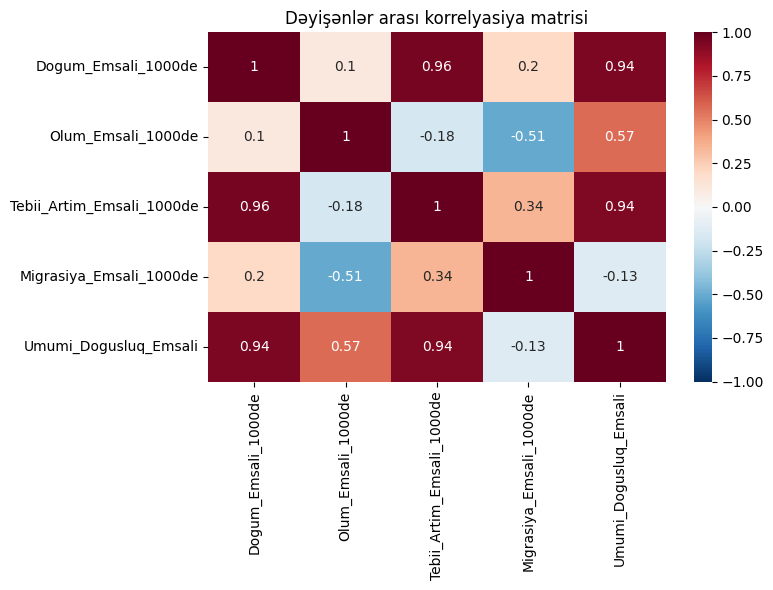

In [17]:
cols = ['Dogum_Emsali_1000de','Olum_Emsali_1000de','Tebii_Artim_Emsali_1000de',
        'Migrasiya_Emsali_1000de','Umumi_Dogusluq_Emsali']

corr_matrix = df[cols].corr(method='pearson')

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Dəyişənlər arası korrelyasiya matrisi')
plt.tight_layout()

In [18]:
df = df.sort_values('Il')
df['Ehali_Artim_Perc'] = df['Ortalama_Ehali'].pct_change() * 100

print(df[['Il','Ortalama_Ehali','Ehali_Artim_Perc']].head(10))

     Il  Ortalama_Ehali  Ehali_Artim_Perc
0  1935         2933800               NaN
1  1936         3004300          2.403027
2  1937         3082600          2.606264
3  1938         3167400          2.750925
4  1939         3205200          1.193408
5  1940         3274000          2.146512
6  1941         3331800          1.765425
7  1942         3157100         -5.243412
8  1943         2918100         -7.570239
9  1944         2776700         -4.845619


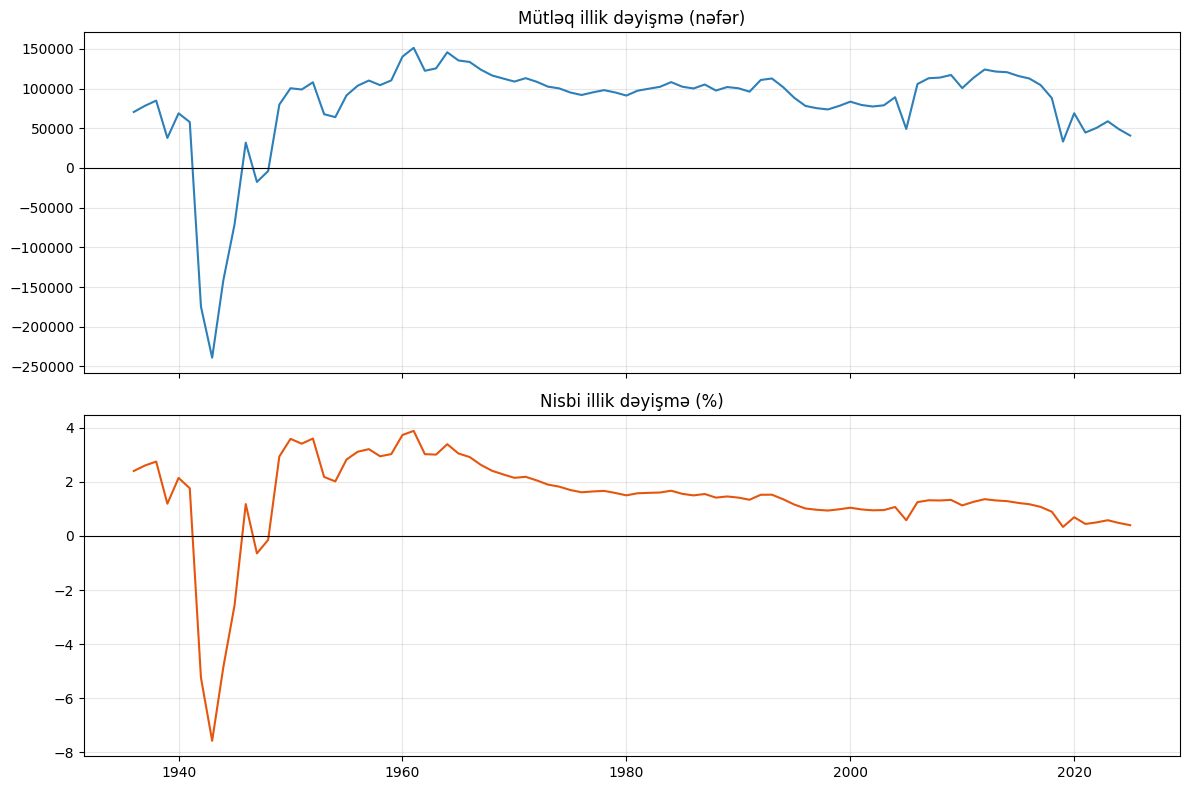

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12,8), sharex=True)

axes[0].plot(df['Il'], df['Ortalama_Ehali'].diff(), color='#2c7fb8')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Mütləq illik dəyişmə (nəfər)')
axes[0].grid(alpha=0.3)

axes[1].plot(df['Il'], df['Ehali_Artim_Perc'], color='#e6550d')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set_title('Nisbi illik dəyişmə (%)')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('artim_muqayise.png')

In [20]:
top5_sureli = df.nlargest(5, 'Ehali_Artim_Perc')[['Il','Ehali_Artim_Perc']]
top5_yavas = df.nsmallest(5, 'Ehali_Artim_Perc')[['Il','Ehali_Artim_Perc']]

print("Ən sürətli artım illəri:\n", top5_sureli)
print("\nƏn yavaş/mənfi artım illəri:\n", top5_yavas)

Ən sürətli artım illəri:
       Il  Ehali_Artim_Perc
26  1961          3.884966
25  1960          3.734385
17  1952          3.602671
15  1950          3.591101
16  1951          3.411367

Ən yavaş/mənfi artım illəri:
       Il  Ehali_Artim_Perc
8   1943         -7.570239
7   1942         -5.243412
9   1944         -4.845619
10  1945         -2.560594
12  1947         -0.642922


In [21]:
dovrler = {
    'Erkən Sovet (1935-1960)': (1935, 1960),
    'Gec Sovet (1961-1990)': (1961, 1990),
    'Keçid dövrü (1991-2003)': (1991, 2003),
    'Müasir dövr (2004-2025)': (2004, 2025)
}

for ad, (bas, son) in dovrler.items():
    mask = (df['Il']>=bas) & (df['Il']<=son)
    orta_artim = df[mask]['Ehali_Artim_Perc'].mean()
    print(f"{ad}: orta illik artım = {orta_artim:.2f}%")

Erkən Sovet (1935-1960): orta illik artım = 1.19%
Gec Sovet (1961-1990): orta illik artım = 2.06%
Keçid dövrü (1991-2003): orta illik artım = 1.14%
Müasir dövr (2004-2025): orta illik artım = 0.96%


In [22]:
df['Ehali_Artim_Perc'] = df['Ortalama_Ehali'].pct_change() * 100

feat = ['Dogum_Emsali_1000de', 'Olum_Emsali_1000de',
        'Tebii_Artim_Emsali_1000de', 'Ehali_Artim_Perc']
d = df.dropna(subset=feat).copy()   

Xs = StandardScaler().fit_transform(d[feat])

for k in range(2, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    print(k, round(km.inertia_, 1), round(silhouette_score(Xs, km.labels_), 3))

km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xs)
d['Klaster'] = km.labels_

print(d.groupby('Klaster')[feat].mean().round(2))
for c, g in d.groupby('Klaster'):
    print(c, len(g), list(g['Il']))

2 214.4 0.45
3 113.8 0.511
4 69.0 0.521
5 39.4 0.586
6 32.1 0.582
7 27.2 0.519
         Dogum_Emsali_1000de  Olum_Emsali_1000de  Tebii_Artim_Emsali_1000de  \
Klaster                                                                       
0                      27.01                8.11                      18.89   
1                      15.51                6.06                       9.45   
2                      13.65               15.45                      -1.80   
3                      37.95                7.37                      30.57   

         Ehali_Artim_Perc  
Klaster                    
0                    1.73  
1                    0.98  
2                   -5.05  
3                    3.07  
0 37 [1936, 1937, 1938, 1939, 1940, 1941, 1946, 1947, 1948, 1949, 1950, 1953, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993]
1 32 [1994, 1995, 1996, 1997, 1998, 1999, 2000, 20

In [23]:
df = df.sort_values('Il').set_index('Il')

def rmse(a, b): return float(np.sqrt(np.mean((np.array(a)-np.array(b))**2)))
def mape(a, b): return float(np.mean(np.abs((np.array(a)-np.array(b))/np.array(a)))*100)

def linear_fc(s, years):
    X = sm.add_constant(s.index.values.astype(float))
    m = sm.OLS(s.values, X).fit()
    Xf = sm.add_constant(np.array(years, dtype=float), has_constant='add')
    return m.predict(Xf), m

def best_arima(s, orders):
    best = None
    for o in orders:
        try:
            r = ARIMA(s.values, order=o).fit()
            if best is None or r.aic < best[1].aic:
                best = (o, r)
        except Exception:
            pass
    return best

orders = [(p, d, q) for p in range(3) for d in (1, 2) for q in range(3)]

s = df.loc[1994:, 'Ortalama_Ehali'].dropna()      

tr, te = s.loc[:2020], s.loc[2021:]
lp, _ = linear_fc(tr, te.index)
o, r = best_arima(tr, orders)
ap = r.forecast(len(te))
print("Xətti :", rmse(te, lp), mape(te, lp))
print("ARIMA", o, ":", rmse(te, ap), mape(te, ap))

o2, r2 = best_arima(s, orders)
fc = r2.get_forecast(5)
print(fc.predicted_mean)
print(fc.conf_int(alpha=0.05))      

c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\ASUS\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood 

Xətti : 169875.20316636516 1.539769617798001
ARIMA (0, 2, 0) : 64369.2939218693 0.5770750545255862
[10284400. 10325200. 10366000. 10406800. 10447600.]
[[10247699.55990579 10321100.44009421]
 [10243135.32114518 10407264.67885482]
 [10228679.52722364 10503320.47277636]
 [10205783.41090033 10607816.58909967]
 [10175422.25169756 10719777.74830244]]


In [24]:
r_final = ARIMA(s.values, order=(0, 2, 0)).fit()
print(r_final.mle_retvals)   

{'fopt': np.float64(10.584271682191616), 'gopt': array([-3.33741931e-06]), 'fcalls': 2, 'warnflag': 0, 'converged': True, 'iterations': 0}


In [25]:
print(r2.mle_retvals['converged'])  

True
